#Modelling: Baseline and Class Weights

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

X_train = pd.read_csv("/content/drive/MyDrive/X_train.csv")
X_test = pd.read_csv("/content/drive/MyDrive/X_test.csv")
y_train = pd.read_csv("/content/drive/MyDrive/y_train.csv")["Class"]
y_test = pd.read_csv("/content/drive/MyDrive/y_test.csv")["Class"]

print(X_train.shape, X_test.shape)

Mounted at /content/drive
(226980, 30) (56746, 30)


An Evaluation Function (reused for every model)

In [2]:
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

def evaluate(model, name):
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print(name)
    print(classification_report(y_test, pred, digits=3))
    print(confusion_matrix(y_test, pred))
    print("PR-AUC:", round(average_precision_score(y_test, proba), 3))

Baseline model: Logistic Regression with no imbalance handling.

In [3]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
evaluate(lr, "Logistic Regression (baseline)")

Logistic Regression (baseline)
              precision    recall  f1-score   support

           0      0.999     1.000     1.000     56651
           1      0.848     0.589     0.696        95

    accuracy                          0.999     56746
   macro avg      0.924     0.795     0.848     56746
weighted avg      0.999     0.999     0.999     56746

[[56641    10]
 [   39    56]]
PR-AUC: 0.692


Same model with class_weight="balanced", so errors on fraud cost more

In [4]:
lr_w = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_w.fit(X_train, y_train)
evaluate(lr_w, "Logistic Regression (class weights)")

Logistic Regression (class weights)
              precision    recall  f1-score   support

           0      1.000     0.975     0.987     56651
           1      0.056     0.874     0.106        95

    accuracy                          0.975     56746
   macro avg      0.528     0.925     0.547     56746
weighted avg      0.998     0.975     0.986     56746

[[55258  1393]
 [   12    83]]
PR-AUC: 0.672


SMOTE creates synthetic fraud examples. It is applied to the training set only, so the test set stays realistic.

In [5]:
from imblearn.over_sampling import SMOTE

X_res, y_res = SMOTE(random_state=42).fit_resample(X_train, y_train)
print(y_res.value_counts())

lr_s = LogisticRegression(max_iter=1000)
lr_s.fit(X_res, y_res)
evaluate(lr_s, "Logistic Regression (SMOTE)")

Class
0    226602
1    226602
Name: count, dtype: int64
Logistic Regression (SMOTE)
              precision    recall  f1-score   support

           0      1.000     0.974     0.987     56651
           1      0.053     0.874     0.100        95

    accuracy                          0.974     56746
   macro avg      0.526     0.924     0.543     56746
weighted avg      0.998     0.974     0.985     56746

[[55169  1482]
 [   12    83]]
PR-AUC: 0.677


Decision Tree with balanced class weights and limited depth to avoid overfitting.

In [6]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)
dt.fit(X_train, y_train)
evaluate(dt, "Decision Tree")

Decision Tree
              precision    recall  f1-score   support

           0      1.000     0.981     0.990     56651
           1      0.068     0.832     0.126        95

    accuracy                          0.981     56746
   macro avg      0.534     0.906     0.558     56746
weighted avg      0.998     0.981     0.989     56746

[[55573  1078]
 [   16    79]]
PR-AUC: 0.47


Random Forest with balanced class weights.

In [7]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
evaluate(rf, "Random Forest")

Random Forest
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.971     0.705     0.817        95

    accuracy                          0.999     56746
   macro avg      0.985     0.853     0.908     56746
weighted avg      0.999     0.999     0.999     56746

[[56649     2]
 [   28    67]]
PR-AUC: 0.798


XGBoost with scale_pos_weight set to the normal-to-fraud ratio.

In [8]:
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
evaluate(xgb, "XGBoost")

XGBoost
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.738     0.800     0.768        95

    accuracy                          0.999     56746
   macro avg      0.869     0.900     0.884     56746
weighted avg      0.999     0.999     0.999     56746

[[56624    27]
 [   19    76]]
PR-AUC: 0.804


Comparison of all models on the untouched test set. PR-AUC and recall matter most for imbalanced fraud data.

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

models = {"LR baseline": lr, "LR class weights": lr_w, "LR SMOTE": lr_s,
          "Decision Tree": dt, "Random Forest": rf, "XGBoost": xgb}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append([name, precision_score(y_test, pred), recall_score(y_test, pred),
                 f1_score(y_test, pred), average_precision_score(y_test, proba)])

results = pd.DataFrame(rows, columns=["Model", "Precision", "Recall", "F1", "PR-AUC"]).round(3)
results.sort_values("PR-AUC", ascending=False)

,Model,Precision,Recall,F1,PR-AUC
5,XGBoost,0.738,0.800,0.768,0.804
4,Random Forest,0.971,0.705,0.817,0.798
0,LR baseline,0.848,0.589,0.696,0.692
2,LR SMOTE,0.053,0.874,0.100,0.677
1,LR class weights,0.056,0.874,0.106,0.672
3,Decision Tree,0.068,0.832,0.126,0.470


Confusion Matrices

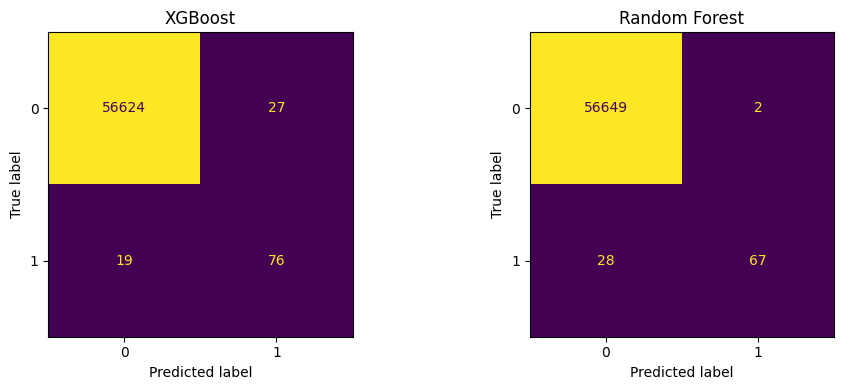

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, [("XGBoost", xgb), ("Random Forest", rf)]):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

Precision-Recall Curves

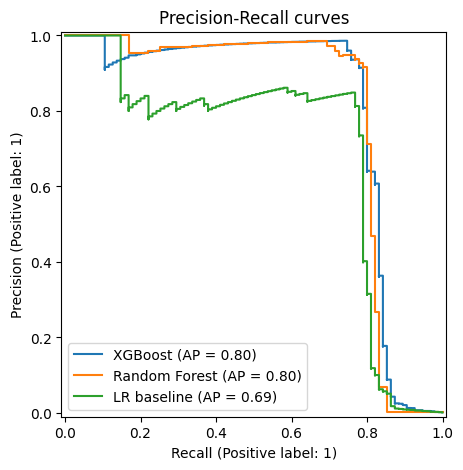

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in [("XGBoost", xgb), ("Random Forest", rf), ("LR baseline", lr)]:
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
plt.title("Precision-Recall curves")
plt.show()

Top Features

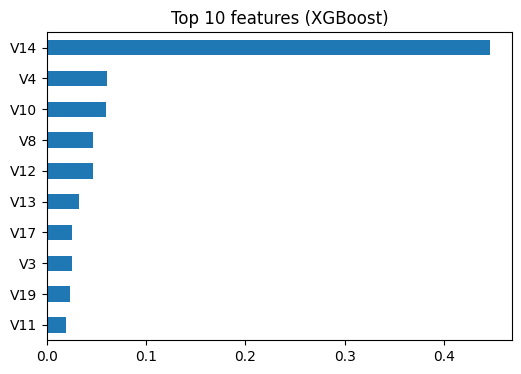

In [12]:
imp = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values().tail(10)
imp.plot(kind="barh", figsize=(6, 4))
plt.title("Top 10 features (XGBoost)")
plt.show()

#**Conclusion**
XGBoost performed best overall (PR-AUC 0.804, recall 0.80, precision 0.74), catching 76 of 95 frauds with 27 false alarms. Random Forest was more precise (0.97, only 2 false alarms) but caught fewer frauds (recall 0.705). Logistic Regression with class weights or SMOTE reached high recall (0.87) but very low precision (about 0.05), producing around 1,400 to 1,500 false alarms. The Decision Tree was weakest (PR-AUC 0.47). Accuracy was about 99.9% for the best models, so it was not used to compare them. Limitation: the test set contains only 95 fraud cases, so the differences between the top two models are small.